<a href="https://colab.research.google.com/github/SrustiUB/Data-Science/blob/main/Spread_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# ==========================================================
# PART 1
# OPTIMAL SPREAD PREDICTION USING CNN-LSTM
# FILE UPLOAD + DATA IMPORT + INSPECTION
# ==========================================================

import pandas as pd
import numpy as np
from google.colab import files

# ==========================================================
# 1. UPLOAD DATA
# ==========================================================

uploaded = files.upload()

print("=" * 70)
print("FILES UPLOADED")
print("=" * 70)

print(
    list(uploaded.keys())
)

# ==========================================================
# 2. IDENTIFY DEPTH CSV
# ==========================================================

depth_files = [
    filename
    for filename in uploaded.keys()
    if "Depth" in filename
    and filename.endswith(".csv")
]

if len(depth_files) == 0:

    raise FileNotFoundError(
        "No BTCUSDT Depth CSV file found. "
        "Please upload BTCUSDT_Depth_1Hour.csv"
    )

depth_file = depth_files[0]

print()
print(
    "Using depth file:",
    depth_file
)

# ==========================================================
# 3. LOAD DATA
# ==========================================================

depth_df = pd.read_csv(
    depth_file
)

# ==========================================================
# 4. CONVERT TIMESTAMP
# ==========================================================

depth_df["timestamp"] = pd.to_datetime(
    depth_df["timestamp"]
)

# ==========================================================
# 5. SORT CHRONOLOGICALLY
# ==========================================================

depth_df = (
    depth_df
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# ==========================================================
# 6. BASIC INFORMATION
# ==========================================================

print()
print("=" * 70)
print("BTCUSDT LEVEL-2 ORDER BOOK")
print("=" * 70)

print()

print(
    "File:",
    depth_file
)

print(
    "Shape:",
    depth_df.shape
)

print()

print(
    "Start:",
    depth_df["timestamp"].min()
)

print(
    "End:",
    depth_df["timestamp"].max()
)

# ==========================================================
# 7. COLUMN INFORMATION
# ==========================================================

print()
print("=" * 70)
print("DEPTH COLUMNS")
print("=" * 70)

for i, column in enumerate(
    depth_df.columns
):

    print(
        i,
        "-",
        column
    )

# ==========================================================
# 8. MISSING VALUES
# ==========================================================

print()
print("=" * 70)
print("MISSING VALUES")
print("=" * 70)

missing = (
    depth_df
    .isna()
    .sum()
    .sort_values(
        ascending=False
    )
)

missing_nonzero = missing[
    missing > 0
]

if len(missing_nonzero) == 0:

    print(
        "No missing values detected."
    )

else:

    print(
        missing_nonzero
    )

# ==========================================================
# 9. DUPLICATE TIMESTAMPS
# ==========================================================

duplicate_timestamps = (
    depth_df["timestamp"]
    .duplicated()
    .sum()
)

print()
print(
    "Duplicate timestamps:",
    duplicate_timestamps
)

# ==========================================================
# 10. OBSERVED SPREAD
# ==========================================================

depth_df["Spread"] = (

    depth_df["best_ask"]

    -

    depth_df["best_bid"]

)

# ==========================================================
# 11. MID PRICE
# ==========================================================

depth_df["MidPrice"] = (

    depth_df["best_bid"]

    +

    depth_df["best_ask"]

) / 2

# ==========================================================
# 12. INVALID ORDER BOOK CHECK
# ==========================================================

invalid_spread = (
    depth_df["Spread"] <= 0
).sum()

crossed_book = (
    depth_df["best_bid"]
    >=
    depth_df["best_ask"]
).sum()

print()
print("=" * 70)
print("ORDER BOOK VALIDATION")
print("=" * 70)

print(
    "Invalid spreads:",
    invalid_spread
)

print(
    "Crossed books:",
    crossed_book
)

# ==========================================================
# 13. SPREAD SUMMARY
# ==========================================================

print()
print("=" * 70)
print("SPREAD & MID-PRICE SUMMARY")
print("=" * 70)

print(
    depth_df[
        [
            "best_bid",
            "best_ask",
            "Spread",
            "MidPrice"
        ]
    ].describe()
)

# ==========================================================
# 14. DATA PREVIEW
# ==========================================================

print()
print("=" * 70)
print("DATA PREVIEW")
print("=" * 70)

print(
    depth_df[
        [
            "timestamp",
            "best_bid",
            "best_bid_qty",
            "best_ask",
            "best_ask_qty",
            "Spread",
            "MidPrice"
        ]
    ].head(10)
)

# ==========================================================
# 15. FINAL STATUS
# ==========================================================

print()
print("=" * 70)
print("PART 1 COMPLETED SUCCESSFULLY")
print("=" * 70)

print(
    "Rows:",
    len(depth_df)
)

print(
    "Columns:",
    len(depth_df.columns)
)

print(
    "Depth file:",
    depth_file
)

Saving BTCUSDT_Depth_1Hour.csv to BTCUSDT_Depth_1Hour.csv
FILES UPLOADED
['BTCUSDT_Depth_1Hour.csv']

Using depth file: BTCUSDT_Depth_1Hour.csv

BTCUSDT LEVEL-2 ORDER BOOK

File: BTCUSDT_Depth_1Hour.csv
Shape: (35901, 45)

Start: 2024-03-01 00:00:00.089000
End: 2024-03-01 00:59:59.966000

DEPTH COLUMNS
0 - timestamp
1 - best_bid
2 - best_bid_qty
3 - best_ask
4 - best_ask_qty
5 - bid_price_1
6 - bid_qty_1
7 - ask_price_1
8 - ask_qty_1
9 - bid_price_2
10 - bid_qty_2
11 - ask_price_2
12 - ask_qty_2
13 - bid_price_3
14 - bid_qty_3
15 - ask_price_3
16 - ask_qty_3
17 - bid_price_4
18 - bid_qty_4
19 - ask_price_4
20 - ask_qty_4
21 - bid_price_5
22 - bid_qty_5
23 - ask_price_5
24 - ask_qty_5
25 - bid_price_6
26 - bid_qty_6
27 - ask_price_6
28 - ask_qty_6
29 - bid_price_7
30 - bid_qty_7
31 - ask_price_7
32 - ask_qty_7
33 - bid_price_8
34 - bid_qty_8
35 - ask_price_8
36 - ask_qty_8
37 - bid_price_9
38 - bid_qty_9
39 - ask_price_9
40 - ask_qty_9
41 - bid_price_10
42 - bid_qty_10
43 - ask_price_10

In [ ]:
# ==========================================================
# PART 2
# ADVANCED LOB FEATURE ENGINEERING
# OPTIMAL SPREAD PREDICTION USING CNN-LSTM
# ==========================================================

import numpy as np
import pandas as pd

EPS = 1e-10

# ==========================================================
# 1. BASIC PRICE FEATURES
# ==========================================================

depth_df["MidPrice"] = (
    depth_df["best_bid"] +
    depth_df["best_ask"]
) / 2

depth_df["Spread"] = (
    depth_df["best_ask"] -
    depth_df["best_bid"]
)

depth_df["Relative_Spread"] = (
    depth_df["Spread"] /
    (depth_df["MidPrice"] + EPS)
)

# ==========================================================
# 2. MICROPRICE
# ==========================================================

depth_df["Microprice"] = (

    (
        depth_df["best_ask"] *
        depth_df["best_bid_qty"]
    )
    +
    (
        depth_df["best_bid"] *
        depth_df["best_ask_qty"]
    )

) / (

    depth_df["best_bid_qty"] +
    depth_df["best_ask_qty"] +
    EPS

)

# ==========================================================
# 3. TOP-OF-BOOK QUEUE IMBALANCE
# ==========================================================

depth_df["Queue_Imbalance"] = (

    (
        depth_df["best_bid_qty"] -
        depth_df["best_ask_qty"]
    )

    /

    (
        depth_df["best_bid_qty"] +
        depth_df["best_ask_qty"] +
        EPS
    )

)

# ==========================================================
# 4. TEN-LEVEL DEPTH
# ==========================================================

bid_qty_cols = [
    f"bid_qty_{i}"
    for i in range(1, 11)
]

ask_qty_cols = [
    f"ask_qty_{i}"
    for i in range(1, 11)
]

depth_df["BidDepth"] = (
    depth_df[bid_qty_cols]
    .sum(axis=1)
)

depth_df["AskDepth"] = (
    depth_df[ask_qty_cols]
    .sum(axis=1)
)

depth_df["TotalDepth"] = (
    depth_df["BidDepth"] +
    depth_df["AskDepth"]
)

# ==========================================================
# 5. DEPTH IMBALANCE
# ==========================================================

depth_df["Depth_Imbalance"] = (

    (
        depth_df["BidDepth"] -
        depth_df["AskDepth"]
    )

    /

    (
        depth_df["TotalDepth"] +
        EPS
    )

)

# ==========================================================
# 6. WEIGHTED DEPTH
# ==========================================================

depth_df["Weighted_BidDepth"] = 0.0

depth_df["Weighted_AskDepth"] = 0.0

for level in range(1, 11):

    depth_df["Weighted_BidDepth"] += (

        depth_df[
            f"bid_qty_{level}"
        ]

        /

        level

    )

    depth_df["Weighted_AskDepth"] += (

        depth_df[
            f"ask_qty_{level}"
        ]

        /

        level

    )

# ==========================================================
# 7. LIQUIDITY IMBALANCE
# ==========================================================

depth_df["Liquidity_Imbalance"] = (

    (
        depth_df["Weighted_BidDepth"] -
        depth_df["Weighted_AskDepth"]
    )

    /

    (
        depth_df["Weighted_BidDepth"] +
        depth_df["Weighted_AskDepth"] +
        EPS
    )

)

# ==========================================================
# 8. ORDER BOOK PRESSURE
# ==========================================================

depth_df["OrderBook_Pressure"] = (

    depth_df["Weighted_BidDepth"]

    -

    depth_df["Weighted_AskDepth"]

)

depth_df["Market_Pressure"] = (

    depth_df["BidDepth"]

    /

    (
        depth_df["TotalDepth"] +
        EPS
    )

)

# ==========================================================
# 9. ORDER FLOW IMBALANCE
# ==========================================================

depth_df["Bid_Qty_Change"] = (
    depth_df["best_bid_qty"].diff()
)

depth_df["Ask_Qty_Change"] = (
    depth_df["best_ask_qty"].diff()
)

depth_df["Bid_Price_Change"] = (
    depth_df["best_bid"].diff()
)

depth_df["Ask_Price_Change"] = (
    depth_df["best_ask"].diff()
)

depth_df["OFI"] = (

    depth_df["Bid_Qty_Change"]

    -

    depth_df["Ask_Qty_Change"]

)

# ==========================================================
# 10. ROLLING OFI
# ==========================================================

depth_df["OFI_5"] = (
    depth_df["OFI"]
    .rolling(5)
    .mean()
)

depth_df["OFI_10"] = (
    depth_df["OFI"]
    .rolling(10)
    .mean()
)

depth_df["OFI_20"] = (
    depth_df["OFI"]
    .rolling(20)
    .mean()
)

# ==========================================================
# 11. SHORT-TERM PRICE RETURNS
# ==========================================================

depth_df["Return_1"] = (
    depth_df["MidPrice"]
    .pct_change()
)

depth_df["Return_5"] = (
    depth_df["MidPrice"]
    .pct_change(5)
)

depth_df["Return_10"] = (
    depth_df["MidPrice"]
    .pct_change(10)
)

# ==========================================================
# 12. SHORT-TERM VOLATILITY
# ==========================================================

depth_df["Volatility_10"] = (
    depth_df["Return_1"]
    .rolling(10)
    .std()
)

depth_df["Volatility_20"] = (
    depth_df["Return_1"]
    .rolling(20)
    .std()
)

# ==========================================================
# 13. SPREAD DYNAMICS
# ==========================================================

depth_df["Spread_Change"] = (
    depth_df["Spread"].diff()
)

depth_df["Spread_Return"] = (
    depth_df["Spread"]
    .pct_change()
)

depth_df["Spread_Mean_5"] = (
    depth_df["Spread"]
    .rolling(5)
    .mean()
)

depth_df["Spread_Mean_10"] = (
    depth_df["Spread"]
    .rolling(10)
    .mean()
)

depth_df["Spread_Std_10"] = (
    depth_df["Spread"]
    .rolling(10)
    .std()
)

# ==========================================================
# 14. MICROPRICE DEVIATION
# ==========================================================

depth_df["Microprice_Deviation"] = (

    depth_df["Microprice"]

    -

    depth_df["MidPrice"]

)

depth_df["Microprice_Deviation_Relative"] = (

    depth_df["Microprice_Deviation"]

    /

    (
        depth_df["MidPrice"] +
        EPS
    )

)

# ==========================================================
# 15. LIQUIDITY CHANGE
# ==========================================================

depth_df["BidDepth_Change"] = (
    depth_df["BidDepth"].diff()
)

depth_df["AskDepth_Change"] = (
    depth_df["AskDepth"].diff()
)

depth_df["TotalDepth_Change"] = (
    depth_df["TotalDepth"].diff()
)

# ==========================================================
# 16. CLEAN NUMERICAL VALUES
# ==========================================================

feature_columns = [

    "MidPrice",
    "Microprice",

    "Spread",
    "Relative_Spread",

    "Queue_Imbalance",

    "BidDepth",
    "AskDepth",
    "TotalDepth",
    "Depth_Imbalance",

    "Weighted_BidDepth",
    "Weighted_AskDepth",
    "Liquidity_Imbalance",

    "OrderBook_Pressure",
    "Market_Pressure",

    "OFI",
    "OFI_5",
    "OFI_10",
    "OFI_20",

    "Return_1",
    "Return_5",
    "Return_10",

    "Volatility_10",
    "Volatility_20",

    "Spread_Change",
    "Spread_Return",
    "Spread_Mean_5",
    "Spread_Mean_10",
    "Spread_Std_10",

    "Microprice_Deviation",
    "Microprice_Deviation_Relative",

    "BidDepth_Change",
    "AskDepth_Change",
    "TotalDepth_Change"

]

depth_df[feature_columns] = (
    depth_df[feature_columns]
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
)

# ==========================================================
# 17. REMOVE INITIAL ROLLING NaNs
# ==========================================================

depth_df = (
    depth_df
    .dropna(
        subset=feature_columns
    )
    .reset_index(drop=True)
)

# ==========================================================
# 18. FEATURE SUMMARY
# ==========================================================

print("=" * 70)
print("ADVANCED LOB FEATURE SUMMARY")
print("=" * 70)

print()

print(
    "Feature count:",
    len(feature_columns)
)

print(
    "Dataset shape:",
    depth_df.shape
)

print()

print(
    depth_df[
        feature_columns
    ].describe()
)

# ==========================================================
# 19. SAMPLE FEATURES
# ==========================================================

print()
print("=" * 70)
print("FEATURE PREVIEW")
print("=" * 70)

print(
    depth_df[
        [
            "timestamp",
            "Spread",
            "Relative_Spread",
            "Queue_Imbalance",
            "Depth_Imbalance",
            "Liquidity_Imbalance",
            "OFI",
            "Volatility_10",
            "Microprice_Deviation"
        ]
    ].head(10)
)

print()
print("=" * 70)
print("PART 2 COMPLETED")
print("=" * 70)

ADVANCED LOB FEATURE SUMMARY

Feature count: 33
Dataset shape: (4811, 82)

           MidPrice    Microprice       Spread  Relative_Spread  \
count   4811.000000   4811.000000  4811.000000     4.811000e+03   
mean   61479.735288  61262.439382     0.726169     1.177758e-05   
std      170.291102   3652.495330    13.754707     2.222503e-04   
min    61126.005000      0.000000   -36.010000    -5.857190e-04   
25%    61344.817500  61333.104348     0.010000     1.619667e-07   
50%    61509.995000  61509.351938     0.010000     1.625067e-07   
75%    61614.997500  61615.032112     0.010000     1.633835e-07   
max    62018.585000  62397.239130   757.350000     1.221166e-02   

       Queue_Imbalance     BidDepth     AskDepth   TotalDepth  \
count      4811.000000  4811.000000  4811.000000  4811.000000   
mean          0.029821     4.324759     4.354239     8.678999   
std           0.830553     8.319545     8.552581    11.758854   
min          -1.000000     0.000000     0.000000     0.017450

/tmp/ipykernel_1521/2228478738.py:265: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  .pct_change()
/tmp/ipykernel_1521/2228478738.py:270: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  .pct_change(5)
/tmp/ipykernel_1521/2228478738.py:275: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  .pct_change(10)
/tmp/ipykernel_1521/2228478738.py:304: FutureWarning: The default fill_method='pad' in Series.pct_chang

In [ ]:
# ==========================================================
# PART 3 — CORRECTED
# CLEAN FUTURE SPREAD TARGET
# ==========================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("CORRECTED FUTURE SPREAD TARGET")
print("=" * 70)

# ==========================================================
# 1. REMOVE INVALID ORDER BOOK STATES
# ==========================================================

before = len(depth_df)

depth_df = depth_df[
    (depth_df["best_bid"] > 0) &
    (depth_df["best_ask"] > 0) &
    (depth_df["best_ask"] > depth_df["best_bid"])
].copy()

print(
    "Rows after valid bid/ask filter:",
    len(depth_df),
    "of",
    before
)

# ==========================================================
# 2. RECOMPUTE SPREAD
# ==========================================================

depth_df["Spread"] = (
    depth_df["best_ask"]
    -
    depth_df["best_bid"]
)

depth_df["MidPrice"] = (
    depth_df["best_bid"]
    +
    depth_df["best_ask"]
) / 2

# ==========================================================
# 3. REMOVE EXTREME SPREAD OUTLIERS
# ==========================================================
#
# We use the empirical 99.5th percentile rather than
# an arbitrary BTC price threshold.
# ==========================================================

spread_cap = depth_df["Spread"].quantile(0.995)

print(
    "99.5% spread threshold:",
    spread_cap
)

depth_df = depth_df[
    depth_df["Spread"] <= spread_cap
].copy()

# ==========================================================
# 4. FORECAST HORIZON
# ==========================================================

forecast_horizon = 5

# ==========================================================
# 5. CREATE FUTURE SPREAD
# ==========================================================

depth_df["Future_Spread"] = (
    depth_df["Spread"]
    .shift(-forecast_horizon)
)

# ==========================================================
# 6. CREATE FUTURE RELATIVE SPREAD
# ==========================================================

depth_df["Future_Relative_Spread"] = (

    depth_df["Future_Spread"]

    /

    (
        depth_df["MidPrice"]
        + 1e-10
    )

)

# ==========================================================
# 7. CURRENT RELATIVE SPREAD
# ==========================================================

depth_df["Current_Relative_Spread"] = (

    depth_df["Spread"]

    /

    (
        depth_df["MidPrice"]
        + 1e-10
    )

)

# ==========================================================
# 8. FUTURE SPREAD CHANGE
# ==========================================================

depth_df["Future_Spread_Change"] = (

    depth_df["Future_Spread"]

    -

    depth_df["Spread"]

)

# ==========================================================
# 9. SPREAD DIRECTION
# ==========================================================

depth_df["Spread_Direction"] = np.select(

    [

        depth_df["Future_Spread_Change"] > 0,

        depth_df["Future_Spread_Change"] < 0

    ],

    [

        1,

        -1

    ],

    default=0

)

# ==========================================================
# 10. REMOVE INVALID FUTURE TARGETS
# ==========================================================

depth_df = depth_df.dropna(
    subset=[
        "Future_Spread",
        "Future_Relative_Spread"
    ]
).copy()

depth_df = depth_df[
    (depth_df["Future_Spread"] > 0) &
    (depth_df["Future_Relative_Spread"] > 0)
].copy()

depth_df = (
    depth_df
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# ==========================================================
# 11. TARGET SUMMARY
# ==========================================================

print()
print("=" * 70)
print("CLEAN TARGET SUMMARY")
print("=" * 70)

print(
    "Rows:",
    len(depth_df)
)

print(
    "Current spread mean:",
    depth_df["Spread"].mean()
)

print(
    "Future spread mean:",
    depth_df["Future_Spread"].mean()
)

print(
    "Current spread median:",
    depth_df["Spread"].median()
)

print(
    "Future spread median:",
    depth_df["Future_Spread"].median()
)

# ==========================================================
# 12. TARGET DISTRIBUTION
# ==========================================================

print()
print("=" * 70)
print("FUTURE SPREAD DISTRIBUTION")
print("=" * 70)

print(
    depth_df[
        "Future_Spread"
    ].describe()
)

# ==========================================================
# 13. RELATIVE SPREAD DISTRIBUTION
# ==========================================================

print()
print("=" * 70)
print("FUTURE RELATIVE SPREAD")
print("=" * 70)

print(
    depth_df[
        "Future_Relative_Spread"
    ].describe()
)

# ==========================================================
# 14. CORRELATION
# ==========================================================

correlation = depth_df[
    [
        "Spread",
        "Future_Spread",
        "Current_Relative_Spread",
        "Future_Relative_Spread"
    ]
].corr()

print()
print("=" * 70)
print("SPREAD CORRELATION")
print("=" * 70)

print(correlation)

# ==========================================================
# 15. DIRECTION DISTRIBUTION
# ==========================================================

direction_counts = (

    depth_df["Spread_Direction"]

    .map({
        -1: "Spread Decrease",
         0: "No Change",
         1: "Spread Increase"
    })

    .value_counts()

)

print()
print("=" * 70)
print("FUTURE SPREAD DIRECTION")
print("=" * 70)

print(direction_counts)

print()

print(
    (
        direction_counts /
        direction_counts.sum() *
        100
    ).round(2)
)

# ==========================================================
# 16. TARGET PREVIEW
# ==========================================================

print()
print("=" * 70)
print("TARGET PREVIEW")
print("=" * 70)

print(
    depth_df[
        [
            "timestamp",
            "best_bid",
            "best_ask",
            "Spread",
            "Future_Spread",
            "Future_Relative_Spread",
            "Future_Spread_Change",
            "Spread_Direction"
        ]
    ].head(15)
)

# ==========================================================
# 17. FINAL VALIDATION
# ==========================================================

negative_current = (
    depth_df["Spread"] <= 0
).sum()

negative_future = (
    depth_df["Future_Spread"] <= 0
).sum()

print()
print("=" * 70)
print("TARGET VALIDATION")
print("=" * 70)

print(
    "Negative current spreads:",
    negative_current
)

print(
    "Negative future spreads:",
    negative_future
)

print()
print("=" * 70)
print("CORRECTED PART 3 COMPLETED")
print("=" * 70)

CORRECTED FUTURE SPREAD TARGET
Rows after valid bid/ask filter: 3616 of 4806
99.5% spread threshold: 39.681249999997135

CLEAN TARGET SUMMARY
Rows: 3592
Current spread mean: 1.3332711581292653
Future spread mean: 1.3350055679288186
Current spread median: 0.010000000002037268
Future spread median: 0.010000000002037268

FUTURE SPREAD DISTRIBUTION
count    3592.000000
mean        1.335006
std         3.962091
min         0.010000
25%         0.010000
50%         0.010000
75%         0.010000
max        39.450000
Name: Future_Spread, dtype: float64

FUTURE RELATIVE SPREAD
count    3.592000e+03
mean     2.170996e-05
std      6.443118e-05
min      1.619427e-07
25%      1.623623e-07
50%      1.628045e-07
75%      1.635684e-07
max      6.409308e-04
Name: Future_Relative_Spread, dtype: float64

SPREAD CORRELATION
                           Spread  Future_Spread  Current_Relative_Spread  \
Spread                   1.000000      -0.005491                 0.999997   
Future_Spread           -0.005

In [ ]:
# ==========================================================
# PART 4
# CHRONOLOGICAL SPLIT + SCALING
# CNN-LSTM OPTIMAL SPREAD FORECASTING
# ==========================================================

from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# ==========================================================
# 1. DEFINE INPUT FEATURES
# ==========================================================

feature_columns = [

    "MidPrice",
    "Microprice",

    "Spread",
    "Relative_Spread",

    "Queue_Imbalance",

    "BidDepth",
    "AskDepth",
    "TotalDepth",
    "Depth_Imbalance",

    "Weighted_BidDepth",
    "Weighted_AskDepth",
    "Liquidity_Imbalance",

    "OrderBook_Pressure",
    "Market_Pressure",

    "OFI",
    "OFI_5",
    "OFI_10",
    "OFI_20",

    "Return_1",
    "Return_5",
    "Return_10",

    "Volatility_10",
    "Volatility_20",

    "Spread_Change",
    "Spread_Return",
    "Spread_Mean_5",
    "Spread_Mean_10",
    "Spread_Std_10",

    "Microprice_Deviation",
    "Microprice_Deviation_Relative",

    "BidDepth_Change",
    "AskDepth_Change",
    "TotalDepth_Change"

]

# ==========================================================
# 2. SORT DATA
# ==========================================================

depth_df = (
    depth_df
    .sort_values("timestamp")
    .reset_index(drop=True)
)

# ==========================================================
# 3. CHRONOLOGICAL SPLIT
# ==========================================================

n = len(depth_df)

train_end = int(
    n * 0.70
)

validation_end = int(
    n * 0.85
)

train_df = depth_df.iloc[
    :train_end
].copy()

validation_df = depth_df.iloc[
    train_end:validation_end
].copy()

test_df = depth_df.iloc[
    validation_end:
].copy()

print("=" * 70)
print("CHRONOLOGICAL DATA SPLIT")
print("=" * 70)

print(
    "Training:",
    train_df.shape
)

print(
    "Validation:",
    validation_df.shape
)

print(
    "Test:",
    test_df.shape
)

print()

print(
    "Train:",
    train_df["timestamp"].min(),
    "→",
    train_df["timestamp"].max()
)

print(
    "Validation:",
    validation_df["timestamp"].min(),
    "→",
    validation_df["timestamp"].max()
)

print(
    "Test:",
    test_df["timestamp"].min(),
    "→",
    test_df["timestamp"].max()
)

# ==========================================================
# 4. INPUT ARRAYS
# ==========================================================

X_train_raw = train_df[
    feature_columns
].values

X_val_raw = validation_df[
    feature_columns
].values

X_test_raw = test_df[
    feature_columns
].values

# ==========================================================
# 5. LOG TRANSFORM TARGET
# ==========================================================

y_train_raw = train_df[
    "Future_Spread"
].values

y_val_raw = validation_df[
    "Future_Spread"
].values

y_test_raw = test_df[
    "Future_Spread"
].values

y_train_log = np.log1p(
    y_train_raw
)

y_val_log = np.log1p(
    y_val_raw
)

y_test_log = np.log1p(
    y_test_raw
)

# ==========================================================
# 6. FEATURE SCALER
# ==========================================================
#
# IMPORTANT:
# Fit ONLY on training data.
# This prevents look-ahead leakage.
# ==========================================================

feature_scaler = StandardScaler()

X_train_scaled = (
    feature_scaler
    .fit_transform(X_train_raw)
)

X_val_scaled = (
    feature_scaler
    .transform(X_val_raw)
)

X_test_scaled = (
    feature_scaler
    .transform(X_test_raw)
)

# ==========================================================
# 7. TARGET SCALER
# ==========================================================

target_scaler = StandardScaler()

y_train_scaled = (
    target_scaler
    .fit_transform(
        y_train_log.reshape(-1, 1)
    )
    .flatten()
)

y_val_scaled = (
    target_scaler
    .transform(
        y_val_log.reshape(-1, 1)
    )
    .flatten()
)

y_test_scaled = (
    target_scaler
    .transform(
        y_test_log.reshape(-1, 1)
    )
    .flatten()
)

# ==========================================================
# 8. TARGET STATISTICS
# ==========================================================

print()
print("=" * 70)
print("TRANSFORMED TARGET")
print("=" * 70)

print(
    "Raw target mean:",
    y_train_raw.mean()
)

print(
    "Raw target median:",
    np.median(y_train_raw)
)

print(
    "Log target mean:",
    y_train_log.mean()
)

print(
    "Log target std:",
    y_train_log.std()
)

print()

print(
    "Scaled target mean:",
    y_train_scaled.mean()
)

print(
    "Scaled target std:",
    y_train_scaled.std()
)

# ==========================================================
# 9. FEATURE VALIDATION
# ==========================================================

print()
print("=" * 70)
print("FEATURE SCALING CHECK")
print("=" * 70)

print(
    "Training mean:",
    np.nanmean(X_train_scaled)
)

print(
    "Training std:",
    np.nanstd(X_train_scaled)
)

print(
    "Validation mean:",
    np.nanmean(X_val_scaled)
)

print(
    "Test mean:",
    np.nanmean(X_test_scaled)
)

# ==========================================================
# 10. FINAL CHECK
# ==========================================================

print()
print("=" * 70)
print("PART 4 COMPLETED")
print("=" * 70)

print(
    "Features:",
    len(feature_columns)
)

print(
    "Training rows:",
    len(X_train_scaled)
)

print(
    "Validation rows:",
    len(X_val_scaled)
)

print(
    "Test rows:",
    len(X_test_scaled)
)

CHRONOLOGICAL DATA SPLIT
Training: (2514, 88)
Validation: (539, 88)
Test: (539, 88)

Train: 2024-03-01 00:00:02.090000 → 2024-03-01 00:36:32.739000
Validation: 2024-03-01 00:36:32.839000 → 2024-03-01 00:46:44.510000
Test: 2024-03-01 00:46:44.610000 → 2024-03-01 00:59:22.050000

TRANSFORMED TARGET
Raw target mean: 1.18194510739861
Raw target median: 0.010000000002037268
Log target mean: 0.33729817385623734
Log target std: 0.7263572464363154

Scaled target mean: -5.652686839778045e-18
Scaled target std: 1.0000000000000002

FEATURE SCALING CHECK
Training mean: 4.674600722955843e-16
Training std: 1.0
Validation mean: -0.02739505108433427
Test mean: 0.024218152815694352

PART 4 COMPLETED
Features: 33
Training rows: 2514
Validation rows: 539
Test rows: 539


In [ ]:
# ==========================================================
# PART 5
# CREATE CNN-LSTM SEQUENCES
# ==========================================================

import numpy as np

# ==========================================================
# 1. SEQUENCE LENGTH
# ==========================================================

sequence_length = 30

print("=" * 70)
print("CNN-LSTM SEQUENCE CONSTRUCTION")
print("=" * 70)

print(
    "Sequence length:",
    sequence_length
)

print(
    "Number of features:",
    X_train_scaled.shape[1]
)

# ==========================================================
# 2. SEQUENCE CREATION FUNCTION
# ==========================================================

def create_sequences(
    X,
    y,
    sequence_length
):

    X_sequences = []
    y_sequences = []

    for i in range(
        sequence_length,
        len(X)
    ):

        X_sequences.append(

            X[
                i - sequence_length:i
            ]

        )

        y_sequences.append(
            y[i]
        )

    return (

        np.asarray(
            X_sequences,
            dtype=np.float32
        ),

        np.asarray(
            y_sequences,
            dtype=np.float32
        )

    )

# ==========================================================
# 3. TRAINING SEQUENCES
# ==========================================================

X_train_sequences, y_train_sequences = (
    create_sequences(
        X_train_scaled,
        y_train_scaled,
        sequence_length
    )
)

# ==========================================================
# 4. VALIDATION SEQUENCES
# ==========================================================

X_val_sequences, y_val_sequences = (
    create_sequences(
        X_val_scaled,
        y_val_scaled,
        sequence_length
    )
)

# ==========================================================
# 5. TEST SEQUENCES
# ==========================================================

X_test_sequences, y_test_sequences = (
    create_sequences(
        X_test_scaled,
        y_test_scaled,
        sequence_length
    )
)

# ==========================================================
# 6. SHAPE CHECK
# ==========================================================

print()
print("=" * 70)
print("SEQUENCE SHAPES")
print("=" * 70)

print(
    "Training:",
    X_train_sequences.shape,
    y_train_sequences.shape
)

print(
    "Validation:",
    X_val_sequences.shape,
    y_val_sequences.shape
)

print(
    "Test:",
    X_test_sequences.shape,
    y_test_sequences.shape
)

# ==========================================================
# 7. EXPECTED STRUCTURE
# ==========================================================

print()
print("=" * 70)
print("EXPECTED CNN-LSTM INPUT")
print("=" * 70)

print(
    "(Samples, Timesteps, Features)"
)

print(
    "Training input:",
    X_train_sequences.shape
)

# ==========================================================
# 8. CHECK FOR NaN / INF
# ==========================================================

print()
print("=" * 70)
print("SEQUENCE QUALITY CHECK")
print("=" * 70)

print(
    "Train NaN:",
    np.isnan(
        X_train_sequences
    ).sum()
)

print(
    "Validation NaN:",
    np.isnan(
        X_val_sequences
    ).sum()
)

print(
    "Test NaN:",
    np.isnan(
        X_test_sequences
    ).sum()
)

print(
    "Train INF:",
    np.isinf(
        X_train_sequences
    ).sum()
)

print(
    "Validation INF:",
    np.isinf(
        X_val_sequences
    ).sum()
)

print(
    "Test INF:",
    np.isinf(
        X_test_sequences
    ).sum()
)

# ==========================================================
# 9. TARGET CHECK
# ==========================================================

print()
print("=" * 70)
print("TARGET CHECK")
print("=" * 70)

print(
    "Training target mean:",
    y_train_sequences.mean()
)

print(
    "Training target std:",
    y_train_sequences.std()
)

print(
    "Validation target mean:",
    y_val_sequences.mean()
)

print(
    "Test target mean:",
    y_test_sequences.mean()
)

# ==========================================================
# 10. FINAL STATUS
# ==========================================================

print()
print("=" * 70)
print("PART 5 COMPLETED")
print("=" * 70)

print(
    "CNN-LSTM input shape:",
    X_train_sequences.shape
)

print(
    "CNN-LSTM target shape:",
    y_train_sequences.shape
)

CNN-LSTM SEQUENCE CONSTRUCTION
Sequence length: 30
Number of features: 33

SEQUENCE SHAPES
Training: (2484, 30, 33) (2484,)
Validation: (509, 30, 33) (509,)
Test: (509, 30, 33) (509,)

EXPECTED CNN-LSTM INPUT
(Samples, Timesteps, Features)
Training input: (2484, 30, 33)

SEQUENCE QUALITY CHECK
Train NaN: 0
Validation NaN: 0
Test NaN: 0
Train INF: 0
Validation INF: 0
Test INF: 0

TARGET CHECK
Training target mean: 0.003229003
Training target std: 1.0033323
Validation target mean: 0.18084055
Test target mean: 0.16210203

PART 5 COMPLETED
CNN-LSTM input shape: (2484, 30, 33)
CNN-LSTM target shape: (2484,)


In [ ]:
# ==========================================================
# PART 6
# CNN-LSTM MODEL
# OPTIMAL SPREAD FORECASTING
# ==========================================================

import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Input,
    Conv1D,
    BatchNormalization,
    MaxPooling1D,
    LSTM,
    Dense,
    Dropout
)

from tensorflow.keras.optimizers import Adam

# ==========================================================
# 1. MODEL PARAMETERS
# ==========================================================

sequence_length = X_train_sequences.shape[1]

num_features = X_train_sequences.shape[2]

print("=" * 70)
print("CNN-LSTM MODEL")
print("=" * 70)

print(
    "Sequence length:",
    sequence_length
)

print(
    "Number of features:",
    num_features
)

# ==========================================================
# 2. BUILD MODEL
# ==========================================================

cnn_lstm_model = Sequential([

    # ------------------------------------------------------
    # INPUT
    # ------------------------------------------------------

    Input(
        shape=(
            sequence_length,
            num_features
        )
    ),

    # ------------------------------------------------------
    # CNN BLOCK
    # ------------------------------------------------------

    Conv1D(

        filters=64,

        kernel_size=3,

        activation="relu",

        padding="same"

    ),

    BatchNormalization(),

    Conv1D(

        filters=64,

        kernel_size=3,

        activation="relu",

        padding="same"

    ),

    BatchNormalization(),

    MaxPooling1D(
        pool_size=2
    ),

    Dropout(0.20),

    # ------------------------------------------------------
    # LSTM BLOCK
    # ------------------------------------------------------

    LSTM(

        128,

        return_sequences=True

    ),

    Dropout(0.20),

    LSTM(

        64,

        return_sequences=False

    ),

    Dropout(0.20),

    # ------------------------------------------------------
    # DENSE REGRESSION HEAD
    # ------------------------------------------------------

    Dense(

        64,

        activation="relu"

    ),

    Dropout(0.15),

    Dense(

        32,

        activation="relu"

    ),

    # ------------------------------------------------------
    # OUTPUT
    # ------------------------------------------------------

    Dense(

        1,

        activation="linear",

        name="Future_Spread"

    )

])

# ==========================================================
# 3. COMPILE
# ==========================================================

cnn_lstm_model.compile(

    optimizer=Adam(

        learning_rate=0.001

    ),

    loss=tf.keras.losses.Huber(

        delta=1.0

    ),

    metrics=[

        tf.keras.metrics.MeanAbsoluteError(
            name="MAE"
        ),

        tf.keras.metrics.RootMeanSquaredError(
            name="RMSE"
        )

    ]

)

# ==========================================================
# 4. MODEL SUMMARY
# ==========================================================

cnn_lstm_model.summary()

# ==========================================================
# 5. PARAMETER COUNT
# ==========================================================

print()
print("=" * 70)

print(
    "Total parameters:",
    cnn_lstm_model.count_params()
)

print("=" * 70)

print()
print("PART 6 MODEL CREATED SUCCESSFULLY")

CNN-LSTM MODEL
Sequence length: 30
Number of features: 33


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 30, 64)         │         6,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 30, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 30, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 15, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 15, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 15, 128)        │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 15, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Future_Spread (Dense)           │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 173,761 (678.75 KB)

 Trainable params: 173,505 (677.75 KB)

 Non-trainable params: 256 (1.00 KB)


Total parameters: 173761

PART 6 MODEL CREATED SUCCESSFULLY


CNN-LSTM TRAINING
Training samples   : 2484
Validation samples : 509
Test samples       : 509

STARTING TRAINING
Epoch 1/40
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - MAE: 0.5532 - RMSE: 0.9499 - loss: 0.2916
Epoch 1: val_loss improved from None to 0.42657, saving model to CNN_LSTM_Optimal_Spread_Best.keras

Epoch 1: finished saving model to CNN_LSTM_Optimal_Spread_Best.keras
39/39 ━━━━━━━━━━━━━━━━━━━━ 9s 32ms/step - MAE: 0.5941 - RMSE: 1.0312 - loss: 0.3325 - val_MAE: 0.7405 - val_RMSE: 1.1516 - val_loss: 0.4266 - learning_rate: 0.0010
Epoch 2/40
35/39 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - MAE: 0.5506 - RMSE: 0.9306 - loss: 0.2808
Epoch 2: val_loss improved from 0.42657 to 0.42591, saving model to CNN_LSTM_Optimal_Spread_Best.keras

Epoch 2: finished saving model to CNN_LSTM_Optimal_Spread_Best.keras
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - MAE: 0.6044 - RMSE: 1.0265 - loss: 0.3303 - val_MAE: 0.7422 - val_RMSE: 1.1494 - val_loss: 0.4259 - learning_rate: 0.0010
Epoch 3/40
36/39 ━━━━━━━━━

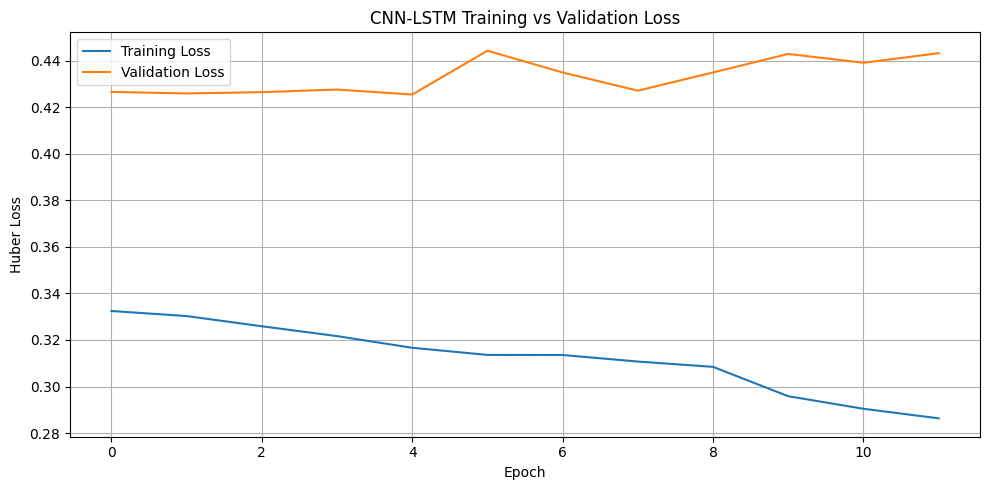

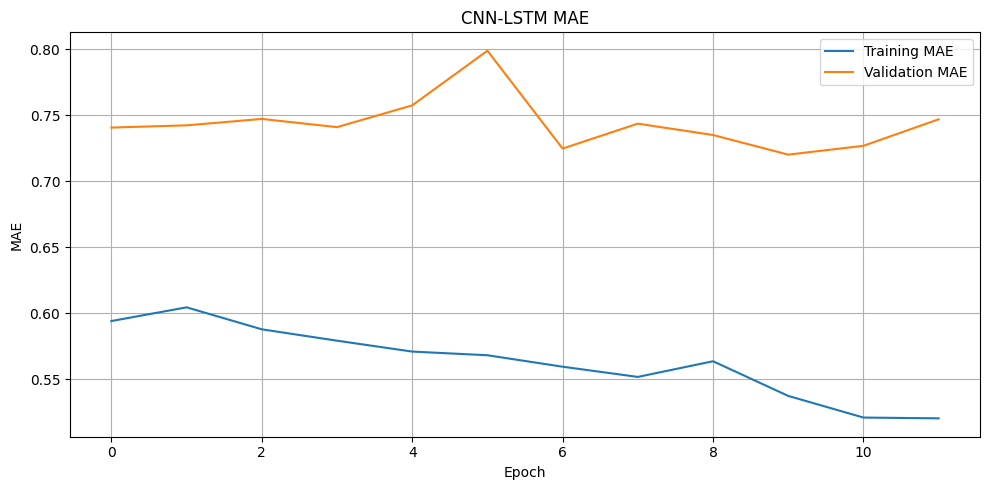

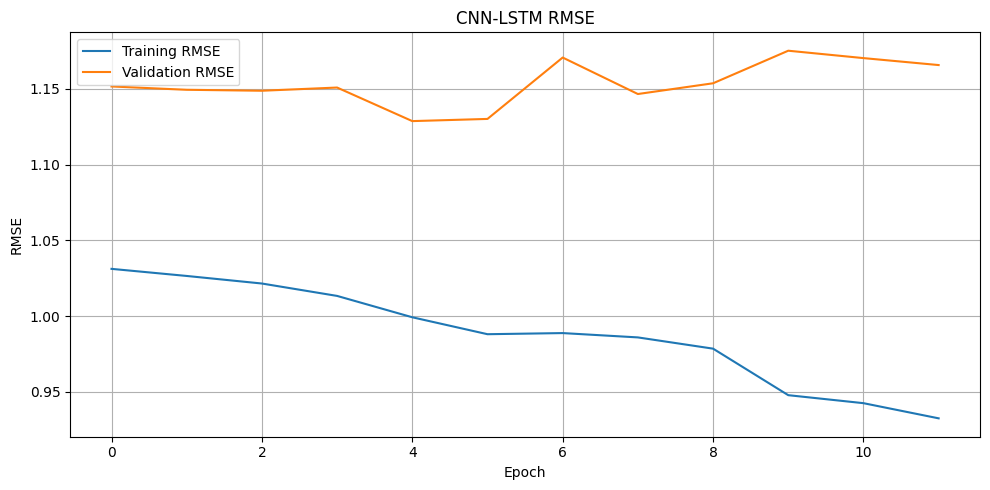


Final learning rate: 0.0002500000118743628

PART 7 COMPLETED


In [ ]:
# ==========================================================
# PART 7
# TRAIN CNN-LSTM
# OPTIMAL SPREAD FORECASTING
# ==========================================================

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# ==========================================================
# 1. TRAINING CONFIGURATION
# ==========================================================

epochs = 40
batch_size = 64

print("=" * 70)
print("CNN-LSTM TRAINING")
print("=" * 70)

print(
    "Training samples   :",
    X_train_sequences.shape[0]
)

print(
    "Validation samples :",
    X_val_sequences.shape[0]
)

print(
    "Test samples       :",
    X_test_sequences.shape[0]
)

# ==========================================================
# 2. CALLBACKS
# ==========================================================

early_stopping = EarlyStopping(

    monitor="val_loss",

    patience=7,

    restore_best_weights=True,

    verbose=1

)

reduce_lr = ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=3,

    min_lr=1e-6,

    verbose=1

)

checkpoint = ModelCheckpoint(

    "CNN_LSTM_Optimal_Spread_Best.keras",

    monitor="val_loss",

    save_best_only=True,

    verbose=1

)

# ==========================================================
# 3. TRAIN MODEL
# ==========================================================

print()
print("=" * 70)
print("STARTING TRAINING")
print("=" * 70)

history = cnn_lstm_model.fit(

    X_train_sequences,

    y_train_sequences,

    validation_data=(

        X_val_sequences,

        y_val_sequences

    ),

    epochs=epochs,

    batch_size=batch_size,

    shuffle=False,

    callbacks=[

        early_stopping,

        reduce_lr,

        checkpoint

    ],

    verbose=1

)

# ==========================================================
# 4. TRAINING SUMMARY
# ==========================================================

print()
print("=" * 70)
print("TRAINING COMPLETED")
print("=" * 70)

print(
    "Epochs completed:",
    len(history.history["loss"])
)

print(
    "Best validation loss:",
    min(
        history.history["val_loss"]
    )
)

# ==========================================================
# 5. FINAL VALIDATION METRICS
# ==========================================================

best_epoch = np.argmin(
    history.history["val_loss"]
) + 1

print(
    "Best epoch:",
    best_epoch
)

print(
    "Best validation MAE:",
    min(
        history.history["val_MAE"]
    )
)

print(
    "Best validation RMSE:",
    min(
        history.history["val_RMSE"]
    )
)

# ==========================================================
# 6. LOSS CURVE
# ==========================================================

plt.figure(figsize=(10, 5))

plt.plot(

    history.history["loss"],

    label="Training Loss"

)

plt.plot(

    history.history["val_loss"],

    label="Validation Loss"

)

plt.title(
    "CNN-LSTM Training vs Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Huber Loss")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# 7. MAE CURVE
# ==========================================================

plt.figure(figsize=(10, 5))

plt.plot(

    history.history["MAE"],

    label="Training MAE"

)

plt.plot(

    history.history["val_MAE"],

    label="Validation MAE"

)

plt.title(
    "CNN-LSTM MAE"
)

plt.xlabel("Epoch")

plt.ylabel("MAE")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# 8. RMSE CURVE
# ==========================================================

plt.figure(figsize=(10, 5))

plt.plot(

    history.history["RMSE"],

    label="Training RMSE"

)

plt.plot(

    history.history["val_RMSE"],

    label="Validation RMSE"

)

plt.title(
    "CNN-LSTM RMSE"
)

plt.xlabel("Epoch")

plt.ylabel("RMSE")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# 9. FINAL LEARNING RATE
# ==========================================================

final_learning_rate = float(

    tf.keras.backend.get_value(

        cnn_lstm_model
        .optimizer
        .learning_rate

    )

)

print()
print(
    "Final learning rate:",
    final_learning_rate
)

print()
print("=" * 70)
print("PART 7 COMPLETED")
print("=" * 70)

GENERATING TEST PREDICTIONS
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step

CNN-LSTM SPREAD FORECASTING RESULTS
MAE      : 1.966810
RMSE     : 5.403858
R²       : -0.073847
Pearson  : 0.045713
Spearman : -0.027341

ACTUAL vs PREDICTED SPREAD
Actual Mean     : 1.807642
Predicted Mean  : 0.370689
Actual Median   : 0.010000
Predicted Median: 0.341976
Actual Std      : 5.214742
Predicted Std   : 0.226443


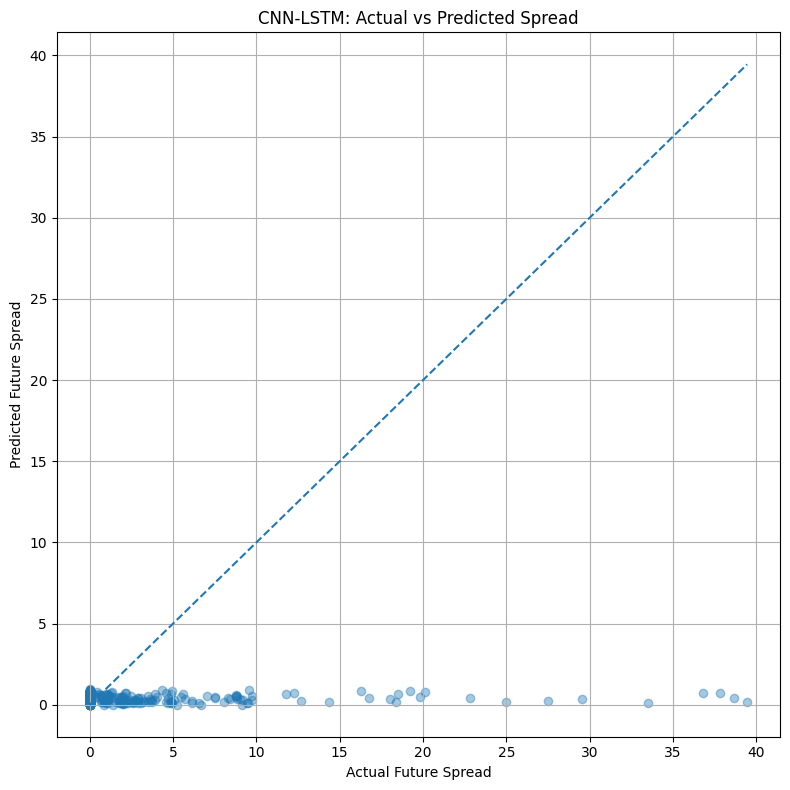

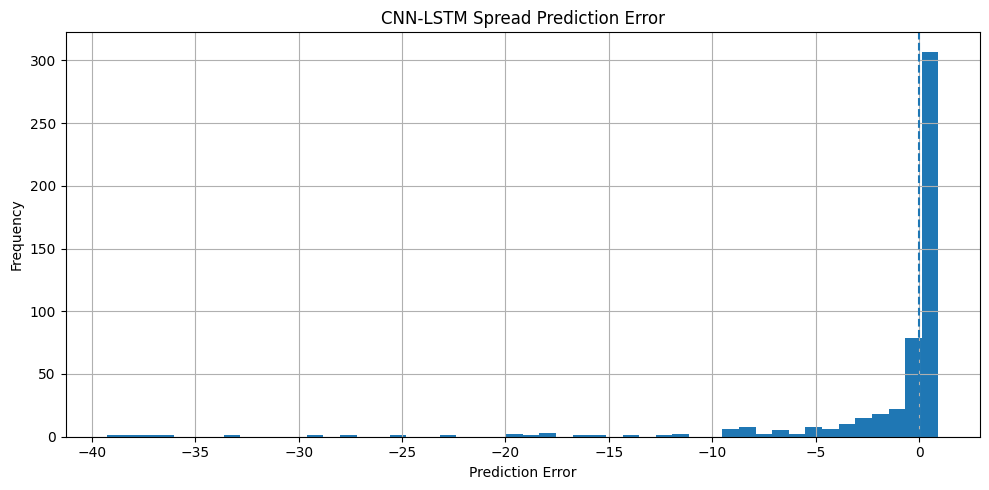


ERROR DISTRIBUTION
count    509.000000
mean      -1.436954
std        5.214429
min      -39.255825
25%       -0.538140
50%        0.239418
75%        0.429512
max        0.936226
dtype: float64

PART 8 COMPLETED


In [ ]:
# ==========================================================
# PART 8
# CNN-LSTM OUT-OF-SAMPLE EVALUATION
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ==========================================================
# 1. GENERATE TEST PREDICTIONS
# ==========================================================

print("=" * 70)
print("GENERATING TEST PREDICTIONS")
print("=" * 70)

y_pred_scaled = (
    cnn_lstm_model.predict(
        X_test_sequences,
        verbose=1
    )
    .reshape(-1)
)

# ==========================================================
# 2. INVERSE TARGET SCALING
# ==========================================================

y_pred_log = target_scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).reshape(-1)

y_actual_log = target_scaler.inverse_transform(
    y_test_sequences.reshape(-1, 1)
).reshape(-1)

# ==========================================================
# 3. REVERSE LOG TRANSFORMATION
# ==========================================================

y_pred_spread = np.expm1(
    y_pred_log
)

y_actual_spread = np.expm1(
    y_actual_log
)

# ==========================================================
# 4. VALIDATION
# ==========================================================

valid = (

    np.isfinite(y_pred_spread)

    &

    np.isfinite(y_actual_spread)

)

y_pred_spread = y_pred_spread[valid]

y_actual_spread = y_actual_spread[valid]

# Spread cannot be negative

y_pred_spread = np.maximum(
    y_pred_spread,
    0
)

# ==========================================================
# 5. ERROR METRICS
# ==========================================================

mae = mean_absolute_error(
    y_actual_spread,
    y_pred_spread
)

rmse = np.sqrt(
    mean_squared_error(
        y_actual_spread,
        y_pred_spread
    )
)

r2 = r2_score(
    y_actual_spread,
    y_pred_spread
)

# ==========================================================
# 6. CORRELATION
# ==========================================================

pearson = np.corrcoef(
    y_actual_spread,
    y_pred_spread
)[0, 1]

actual_rank = (
    pd.Series(
        y_actual_spread
    ).rank()
)

pred_rank = (
    pd.Series(
        y_pred_spread
    ).rank()
)

spearman = np.corrcoef(
    actual_rank,
    pred_rank
)[0, 1]

# ==========================================================
# 7. PRINT RESULTS
# ==========================================================

print()
print("=" * 70)
print("CNN-LSTM SPREAD FORECASTING RESULTS")
print("=" * 70)

print(
    f"MAE      : {mae:.6f}"
)

print(
    f"RMSE     : {rmse:.6f}"
)

print(
    f"R²       : {r2:.6f}"
)

print(
    f"Pearson  : {pearson:.6f}"
)

print(
    f"Spearman : {spearman:.6f}"
)

# ==========================================================
# 8. ACTUAL VS PREDICTED SUMMARY
# ==========================================================

print()
print("=" * 70)
print("ACTUAL vs PREDICTED SPREAD")
print("=" * 70)

print(
    f"Actual Mean     : "
    f"{y_actual_spread.mean():.6f}"
)

print(
    f"Predicted Mean  : "
    f"{y_pred_spread.mean():.6f}"
)

print(
    f"Actual Median   : "
    f"{np.median(y_actual_spread):.6f}"
)

print(
    f"Predicted Median: "
    f"{np.median(y_pred_spread):.6f}"
)

print(
    f"Actual Std      : "
    f"{y_actual_spread.std():.6f}"
)

print(
    f"Predicted Std   : "
    f"{y_pred_spread.std():.6f}"
)

# ==========================================================
# 9. ACTUAL vs PREDICTED PLOT
# ==========================================================

plt.figure(figsize=(8, 8))

plt.scatter(
    y_actual_spread,
    y_pred_spread,
    alpha=0.4
)

min_value = min(
    y_actual_spread.min(),
    y_pred_spread.min()
)

max_value = max(
    y_actual_spread.max(),
    y_pred_spread.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel(
    "Actual Future Spread"
)

plt.ylabel(
    "Predicted Future Spread"
)

plt.title(
    "CNN-LSTM: Actual vs Predicted Spread"
)

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# 10. PREDICTION ERROR
# ==========================================================

errors = (
    y_pred_spread
    -
    y_actual_spread
)

plt.figure(figsize=(10, 5))

plt.hist(
    errors,
    bins=50
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Prediction Error"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "CNN-LSTM Spread Prediction Error"
)

plt.grid(True)

plt.tight_layout()

plt.show()

# ==========================================================
# 11. ERROR SUMMARY
# ==========================================================

print()
print("=" * 70)
print("ERROR DISTRIBUTION")
print("=" * 70)

print(
    pd.Series(errors).describe()
)

# ==========================================================
# 12. SAVE RESULTS
# ==========================================================

spread_results = pd.DataFrame({

    "Metric": [

        "MAE",
        "RMSE",
        "R2",
        "Pearson",
        "Spearman",

        "Actual Mean",
        "Predicted Mean",

        "Actual Median",
        "Predicted Median",

        "Actual Std",
        "Predicted Std"

    ],

    "Value": [

        mae,
        rmse,
        r2,
        pearson,
        spearman,

        y_actual_spread.mean(),
        y_pred_spread.mean(),

        np.median(y_actual_spread),
        np.median(y_pred_spread),

        y_actual_spread.std(),
        y_pred_spread.std()

    ]

})

spread_results.to_csv(
    "CNN_LSTM_Spread_Forecasting_Results.csv",
    index=False
)

print()
print("=" * 70)
print("PART 8 COMPLETED")
print("=" * 70)

In [ ]:
# ==========================================================
# PART 9
# FUTURE SPREAD REGIME CLASSIFICATION
# CNN-LSTM
# ==========================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("FUTURE SPREAD REGIME CONSTRUCTION")
print("=" * 70)

# ==========================================================
# 1. TRAINING-ONLY QUANTILE THRESHOLDS
# ==========================================================

q25 = train_df["Future_Spread"].quantile(0.25)
q50 = train_df["Future_Spread"].quantile(0.50)
q75 = train_df["Future_Spread"].quantile(0.75)

print()
print("Training-only thresholds:")
print(
    f"Q25 : {q25:.6f}"
)

print(
    f"Q50 : {q50:.6f}"
)

print(
    f"Q75 : {q75:.6f}"
)

# ==========================================================
# 2. REGIME FUNCTION
# ==========================================================

def assign_spread_regime(
    spread,
    q25,
    q50,
    q75
):

    if spread <= q25:

        return 0

    elif spread <= q50:

        return 1

    elif spread <= q75:

        return 2

    else:

        return 3

# ==========================================================
# 3. CREATE REGIMES
# ==========================================================

train_df["Spread_Regime"] = (
    train_df["Future_Spread"]
    .apply(
        lambda x:
        assign_spread_regime(
            x,
            q25,
            q50,
            q75
        )
    )
)

validation_df["Spread_Regime"] = (
    validation_df["Future_Spread"]
    .apply(
        lambda x:
        assign_spread_regime(
            x,
            q25,
            q50,
            q75
        )
    )
)

test_df["Spread_Regime"] = (
    test_df["Future_Spread"]
    .apply(
        lambda x:
        assign_spread_regime(
            x,
            q25,
            q50,
            q75
        )
    )
)

# ==========================================================
# 4. REGIME LABELS
# ==========================================================

regime_labels = {

    0: "Tight",

    1: "Normal",

    2: "Wide",

    3: "Extreme"

}

# ==========================================================
# 5. TRAINING DISTRIBUTION
# ==========================================================

print()
print("=" * 70)
print("TRAINING REGIME DISTRIBUTION")
print("=" * 70)

train_distribution = (

    train_df["Spread_Regime"]

    .map(regime_labels)

    .value_counts()

    .reindex(
        [
            "Tight",
            "Normal",
            "Wide",
            "Extreme"
        ],
        fill_value=0
    )

)

print(
    train_distribution
)

print()

print(
    (
        train_distribution /
        train_distribution.sum() *
        100
    ).round(2)
)

# ==========================================================
# 6. VALIDATION DISTRIBUTION
# ==========================================================

print()
print("=" * 70)
print("VALIDATION REGIME DISTRIBUTION")
print("=" * 70)

validation_distribution = (

    validation_df["Spread_Regime"]

    .map(regime_labels)

    .value_counts()

    .reindex(
        [
            "Tight",
            "Normal",
            "Wide",
            "Extreme"
        ],
        fill_value=0
    )

)

print(
    validation_distribution
)

# ==========================================================
# 7. TEST DISTRIBUTION
# ==========================================================

print()
print("=" * 70)
print("TEST REGIME DISTRIBUTION")
print("=" * 70)

test_distribution = (

    test_df["Spread_Regime"]

    .map(regime_labels)

    .value_counts()

    .reindex(
        [
            "Tight",
            "Normal",
            "Wide",
            "Extreme"
        ],
        fill_value=0
    )

)

print(
    test_distribution
)

# ==========================================================
# 8. REGIME SUMMARY
# ==========================================================

regime_summary = pd.DataFrame({

    "Regime": [
        "Tight",
        "Normal",
        "Wide",
        "Extreme"
    ],

    "Lower_Bound": [
        0,
        q25,
        q50,
        q75
    ],

    "Upper_Bound": [
        q25,
        q50,
        q75,
        np.inf
    ]

})

print()
print("=" * 70)
print("SPREAD REGIME DEFINITIONS")
print("=" * 70)

print(
    regime_summary.to_string(
        index=False
    )
)

# ==========================================================
# 9. VALIDATE CLASS COVERAGE
# ==========================================================

all_regimes = set(
    train_df["Spread_Regime"]
)

print()
print(
    "Training classes:",
    sorted(all_regimes)
)

if len(all_regimes) < 4:

    print()
    print(
        "WARNING: Some regimes are absent "
        "from the training set."
    )

# ==========================================================
# 10. SAVE REGIME INFORMATION
# ==========================================================

regime_summary.to_csv(
    "Spread_Regime_Definitions.csv",
    index=False
)

# ==========================================================
# 11. FINAL STATUS
# ==========================================================

print()
print("=" * 70)
print("PART 9 COMPLETED")
print("=" * 70)

print(
    "Target:",
    "Future Spread Regime"
)

print(
    "Classes:",
    4
)

print(
    "Threshold source:",
    "Training data only"
)

FUTURE SPREAD REGIME CONSTRUCTION

Training-only thresholds:
Q25 : 0.010000
Q50 : 0.010000
Q75 : 0.010000

TRAINING REGIME DISTRIBUTION
Spread_Regime
Tight      1972
Normal        0
Wide          0
Extreme     542
Name: count, dtype: int64

Spread_Regime
Tight      78.44
Normal      0.00
Wide        0.00
Extreme    21.56
Name: count, dtype: float64

VALIDATION REGIME DISTRIBUTION
Spread_Regime
Tight      365
Normal       0
Wide         0
Extreme    174
Name: count, dtype: int64

TEST REGIME DISTRIBUTION
Spread_Regime
Tight      384
Normal       0
Wide         0
Extreme    155
Name: count, dtype: int64

SPREAD REGIME DEFINITIONS
 Regime  Lower_Bound  Upper_Bound
  Tight         0.00         0.01
 Normal         0.01         0.01
   Wide         0.01         0.01
Extreme         0.01          inf

Training classes: [0, 3]


PART 9 COMPLETED
Target: Future Spread Regime
Classes: 4
Threshold source: Training data only
